In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

In [ ]:
PROJECT_DIR = Path("/Users/kakulrajput/Documents/Image_Detection")
REPORT_DIR = PROJECT_DIR / "reports"
PREDICTIONS_PATH = (REPORT_DIR / "validation_predictions.csv")
predictions_df = pd.read_csv(PREDICTIONS_PATH)
print("Rows:", len(predictions_df))
print("Columns:", predictions_df.columns.tolist())
display(predictions_df.head())

Rows: 771
Columns: ['path', 'true_label', 'predicted_label', 'unsafe_probability', 'true_class', 'predicted_class', 'correct']


,path,true_label,predicted_label,unsafe_probability,true_class,predicted_class,correct
0,/Users/kakulrajput/Documents/Image_Detection/d...,0,0,0.041331,safe,safe,True
1,/Users/kakulrajput/Documents/Image_Detection/d...,0,0,0.046776,safe,safe,True
2,/Users/kakulrajput/Documents/Image_Detection/d...,0,0,0.125400,safe,safe,True
3,/Users/kakulrajput/Documents/Image_Detection/d...,0,0,0.279730,safe,safe,True
4,/Users/kakulrajput/Documents/Image_Detection/d...,0,0,0.138735,safe,safe,True


In [ ]:
THRESHOLD = 0.45
predictions_df["predicted_at_threshold"] = (
    predictions_df["unsafe_probability"] >= THRESHOLD
).astype(int)

predictions_df["predicted_class_at_threshold"] = (
    predictions_df["predicted_at_threshold"]
    .map({
        0: "safe",
        1: "unsafe",
    })
)

predictions_df["correct_at_threshold"] = (
    predictions_df["true_label"]
    == predictions_df["predicted_at_threshold"]
)

display(
    predictions_df[
        [
            "true_class",
            "unsafe_probability",
            "predicted_class_at_threshold",
            "correct_at_threshold",
        ]
    ].head(10)
)

,true_class,unsafe_probability,predicted_class_at_threshold,correct_at_threshold
0,safe,0.041331,safe,True
1,safe,0.046776,safe,True
2,safe,0.125400,safe,True
3,safe,0.279730,safe,True
4,safe,0.138735,safe,True
5,safe,0.410333,safe,True
6,safe,0.074061,safe,True
7,safe,0.009101,safe,True
8,safe,0.172907,safe,True
9,safe,0.919683,unsafe,False


In [4]:
false_positives = predictions_df[
    (predictions_df["true_label"] == 0)
    & (predictions_df["predicted_at_threshold"] == 1)
].copy()

false_negatives = predictions_df[
    (predictions_df["true_label"] == 1)
    & (predictions_df["predicted_at_threshold"] == 0)
].copy()

print("False positives:", len(false_positives))
print("False negatives:", len(false_negatives))
print("Total errors:", len(false_positives) + len(false_negatives))

False positives: 58
False negatives: 63
Total errors: 121


In [5]:
display(
    false_negatives[
        [
            "path",
            "true_class",
            "unsafe_probability",
        ]
    ].sort_values(
        "unsafe_probability"
    ).head(20)
)

,path,true_class,unsafe_probability
766,/Users/kakulrajput/Documents/Image_Detection/d...,unsafe,0.003323
556,/Users/kakulrajput/Documents/Image_Detection/d...,unsafe,0.004145
394,/Users/kakulrajput/Documents/Image_Detection/d...,unsafe,0.007786
584,/Users/kakulrajput/Documents/Image_Detection/d...,unsafe,0.010652
560,/Users/kakulrajput/Documents/Image_Detection/d...,unsafe,0.011740
669,/Users/kakulrajput/Documents/Image_Detection/d...,unsafe,0.015345
767,/Users/kakulrajput/Documents/Image_Detection/d...,unsafe,0.016461
568,/Users/kakulrajput/Documents/Image_Detection/d...,unsafe,0.024986
559,/Users/kakulrajput/Documents/Image_Detection/d...,unsafe,0.029291
732,/Users/kakulrajput/Documents/Image_Detection/d...,unsafe,0.031884


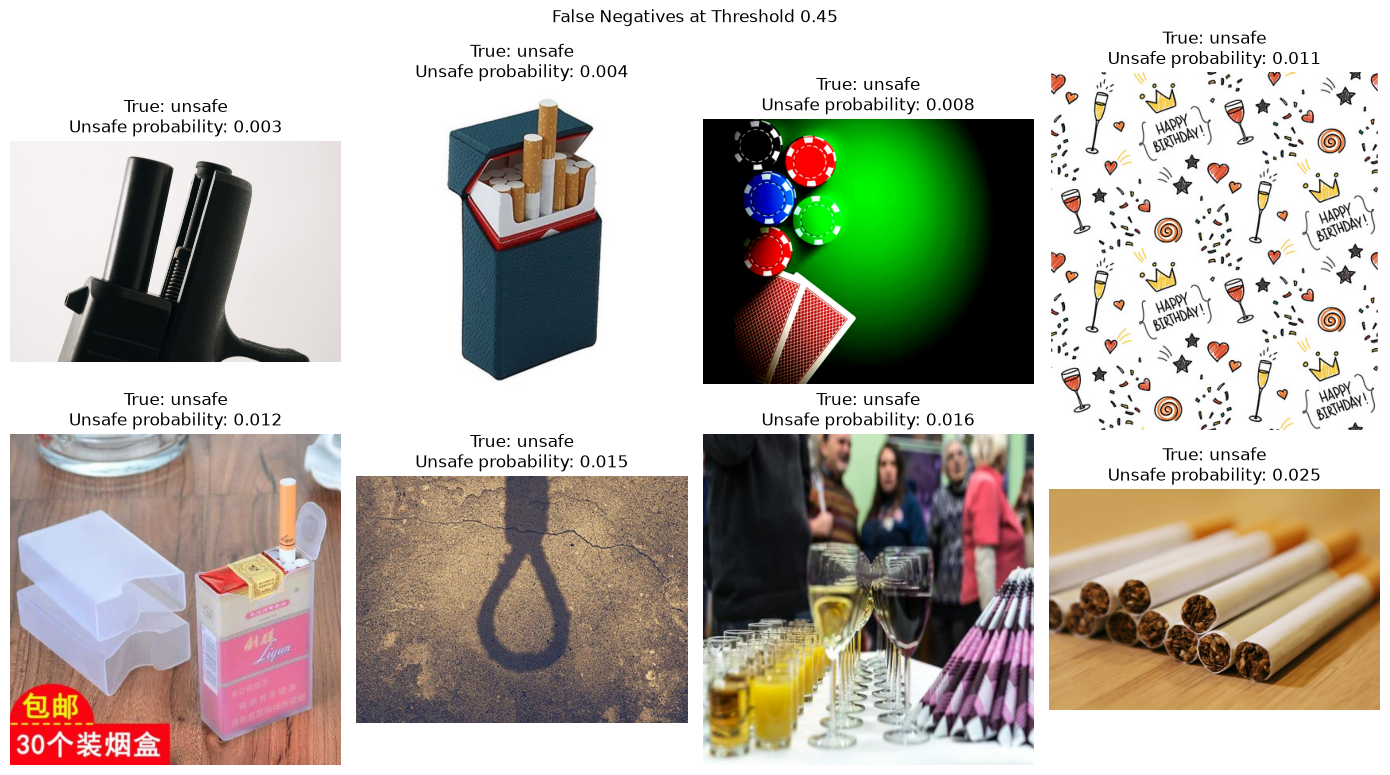

In [ ]:
def show_prediction_examples(dataframe, title, limit=8, figsize=(14, 4)):
    examples = dataframe.head(limit)
    if examples.empty:
        print(f"No examples found for: {title}")
        return

    columns = 4
    rows = int(np.ceil(len(examples) / columns))

    fig, axes = plt.subplots(rows, columns, figsize=figsize,)
    axes = np.atleast_1d(axes).ravel()
    for ax, (_, row) in zip(axes, examples.iterrows()):
        image_path = Path(row["path"])
        try:
            with Image.open(image_path) as image:
                ax.imshow(image.convert("RGB"))
            ax.set_title(
                f"True: {row['true_class']}\n"
                f"Unsafe probability: "
                f"{row['unsafe_probability']:.3f}"
            )
        except Exception as error:
            ax.set_title(f"Could not open image: {error}")
        ax.axis("off")
    for ax in axes[len(examples):]:
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
show_prediction_examples(
    false_negatives.sort_values("unsafe_probability"),
    "False Negatives at Threshold 0.45",
)

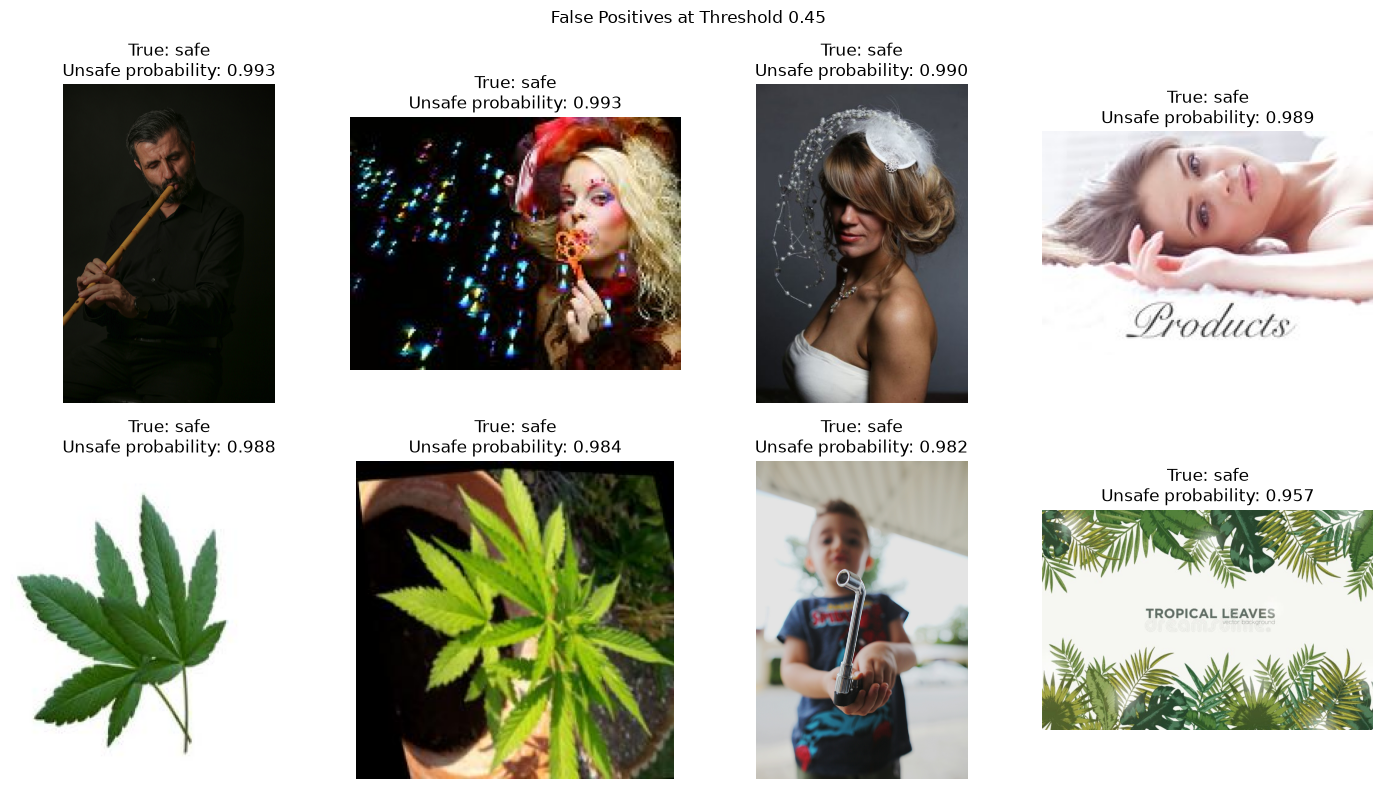

In [7]:
show_prediction_examples(
    false_positives.sort_values(
        "unsafe_probability",
        ascending=False,
    ),
    "False Positives at Threshold 0.45",
)

In [8]:
false_positives.to_csv(
    REPORT_DIR / "false_positives_threshold_045.csv",
    index=False,
)

false_negatives.to_csv(
    REPORT_DIR / "false_negatives_threshold_045.csv",
    index=False,
)

print("Error reports saved successfully.")

Error reports saved successfully.
